### Library change point detectors on population PSTHs (mean change)

Baselines for the PSTH detectors in `CPA_population.ipynb`. The same population PSTHs (sum of k = 10 random trials out of the 100 repeats) are scored with off-the-shelf detectors:

| method | library | what it does |
|---|---|---|
| `sst` | changepoynt `SST(20)` | singular spectrum transformation: how much the dominant subspace of the past Hankel matrix differs from the future one |
| `esst` | changepoynt `ESST(20)` | entropy-based SST |
| `ulsif` | changepoynt `ULSIF(10, 20)` | direct density-ratio estimate (unconstrained least-squares importance fitting) between past and future windows |
| `rulsif` | changepoynt `RuLSIF(10, 20)` | relative (α = 0.01) version of uLSIF, symmetric |
| `edivisive` | ruptures `Dynp` + `CostEnergy` | best single split under the energy statistic (kernel CPD with the distance kernel k(x,y) = \|x\| + \|y\| − \|x − y\|, α = 1) |

For the changepoynt methods the CP is the argmax of the score trace, shifted by a fixed per-method offset (SST +8, ESST +3 bins) because those two peak early even on a clean step. For e-divisive it is the exact best split. Code: `library_cp`, `LIBRARY_METHODS` and `CostEnergy` in `CP_functions.py`, run through `psth_cusum_analysis` (CPA_with_AQUA.py).

Settings: **25 ms bins** from `T_DISCARD` = 200 ms to T = 10 s (392 bins, true CP at bin 192), **k = 10**, **20 resamples per condition**, mean change only. Each bin is count + 1, as in the llr/ks PSTH pipeline. That shift does not affect these detectors much.

uLSIF/RuLSIF use `n_windows = 20` instead of the default 50. The default needs 110 bins of warm-up and costs about twice as much (~5 s instead of ~3 s per PSTH).

In [1]:
import inspect
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
warnings.filterwarnings('ignore')

from CPA_with_AQUA import *

In [2]:
tag = 'N250'
cp = 'mean'
SAVE = True
T_DISCARD = 200     # ms, initial transient
PSTH_BIN = 25       # ms
K = 10              # trials per PSTH
N_RES = 20          # resamples per condition
TOL = 100           # ms, operating point for the hit rate
EXAMPLE_F = [220, 240, 260, 300, 350] #[0, 200, 300, 400]
#METHODS = list(LIBRARY_METHODS)
METHODS = ['edivisive'] # sst, esst, uLSIF, RuLSIF
COLORS = dict(zip(METHODS, sns.color_palette('tab10', len(METHODS))))

sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

with open(f'CPA_cusum_{cp}_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)
T, true_cp = saved['T'], saved['changepoint']
CONDITIONS = [(v, h, f) for v in saved['var'] for h in saved['d_H'] for f in saved['f_values']]
print(f"repeats: {saved['N_repeats']}, T = {T} ms, change point at {true_cp} ms, {len(CONDITIONS)} conditions")


def title_mean(f, v, h):
    return f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\nstep h = {h} pA, var = {v} pA²'


def title_var(f, v, dv):
    return f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\nσ² = {v} → {v + dv} pA² (Δσ² = {dv})'


# change size column, axis label, (variance, step) examples and titles for this cp, as in CPA_population
if cp == 'mean':
    STEP, STEP_LABEL, EXAMPLES, title_cp = 'step_height', 'Step Height [pA]', [(25.0, 3), (12.5, 5)], title_mean
else:
    STEP, STEP_LABEL, EXAMPLES, title_cp = 'variance_step', 'Variance jump Δσ² [pA²]', [(12.5, 50), (25.0, 100)], title_var
assert saved.get('change', 'mean') == cp


def condition_psths(v, h, f, seed = 0):
    '''the N_RES k-trial PSTHs (raw counts) psth_cusum_analysis scored for this condition (same seed)'''
    i = CONDITIONS.index((v, h, f))
    trials = [saved['spikes'][(rep, v, h, f)] for rep in range(saved['N_repeats'])]
    return psth_resamples(trials, K, N_RES, PSTH_BIN, T, T_DISCARD, np.random.default_rng([seed, i]))

repeats: 250, T = 10000 ms, change point at 5000 ms, 3968 conditions


#### Self-check
1. **Alignment** on a clean step at bin 192 (4 to 9, Gaussian noise SD 0.5): with its shift from `LIBRARY_METHODS`, each changepoynt method's median CP must be within 5 bins (125 ms). uLSIF peaks one window either side of a clean step, so its draws fall at about ±5 bins.
2. **Poisson step** (count + 1 rising from 3 + 1 to 8 + 1): printed only. On noisy counts SST often locks onto noise far from the step.
3. **E-divisive on a pure variance step:** it should find it, which a mean-shift cost would not.

In [3]:
t_syn = np.arange(T_DISCARD + PSTH_BIN, T + 1, PSTH_BIN)
rng = np.random.default_rng(0)
clean = [np.r_[np.full(192, 4.), np.full(200, 9.)] + rng.normal(0, 0.5, 392) for _ in range(8)]
poisson = [np.r_[rng.poisson(3, 192), rng.poisson(8, 200)] + 1. for _ in range(8)]
for m in METHODS:
    e_clean = np.median([(library_cp(x, t_syn, PSTH_BIN, m)[0] - true_cp) / PSTH_BIN for x in clean])
    e_pois = [(library_cp(x, t_syn, PSTH_BIN, m)[0] - true_cp) / PSTH_BIN for x in poisson]
    print(f'{m:10s} clean step: median {e_clean:+.1f} bins | Poisson step: median {np.median(e_pois):+.1f}, '
          f'IQR [{np.percentile(e_pois, 25):+.0f}, {np.percentile(e_pois, 75):+.0f}] bins')
    assert abs(e_clean) <= 10, m     # raw, uncorrected output: SST peaks ~8 bins early

syn_var = [np.r_[rng.normal(10, 1, 192), rng.normal(10, 4, 200)] for _ in range(8)]
err = np.median([(library_cp(x, t_syn, PSTH_BIN, 'edivisive')[0] - true_cp) / PSTH_BIN for x in syn_var])
print(f'edivisive on a variance step: median error {err:+.1f} bins')
assert abs(err) <= 5

edivisive  clean step: median +0.0 bins | Poisson step: median +0.0, IQR [+0, +0] bins
edivisive on a variance step: median error +0.0 bins


#### Run the detectors
Takes ~3.5 h on 8 cores, almost all of it uLSIF and RuLSIF (~3 s per PSTH). The other methods take a few minutes. To run it in the background instead:
```
nohup python -W ignore -c "from CPA_with_AQUA import psth_cusum_analysis
for m in ['edivisive', 'esst', 'sst', 'ulsif', 'rulsif']:
    psth_cusum_analysis('CPA_cusum_mean_N100_spikes.pickle', f'CPA_psth_mean_N100_{m}_bin25.pickle', method = m, bin_ms = 25, k_values = (10,), n_resamples = 20)" > library_run.log 2>&1 &
```

In [4]:
RUN = False
if RUN:
    for m in METHODS:
        psth_cusum_analysis(f'CPA_cusum_{cp}_{tag}_spikes.pickle', f'CPA_psth_{cp}_{tag}_{m}_bin{PSTH_BIN}.pickle',
                            method = m, bin_ms = PSTH_BIN, k_values = (K,), n_resamples = N_RES)

## 1. Population summed activity
Summed spike counts of k = 10 trials per 25 ms bin, for the same conditions as the top of `CPA_population.ipynb`. Black: one resample (the first PSTH the detectors scored). Band: mean ± SD over the 20 resamples. Red dashed line: true CP. Grey band: discarded transient (not scored).

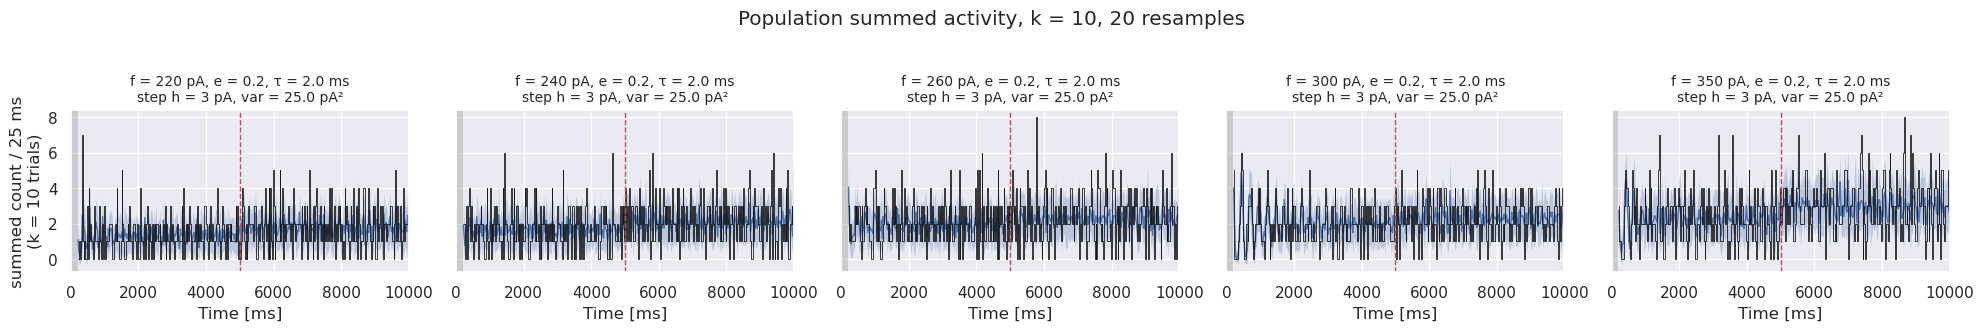

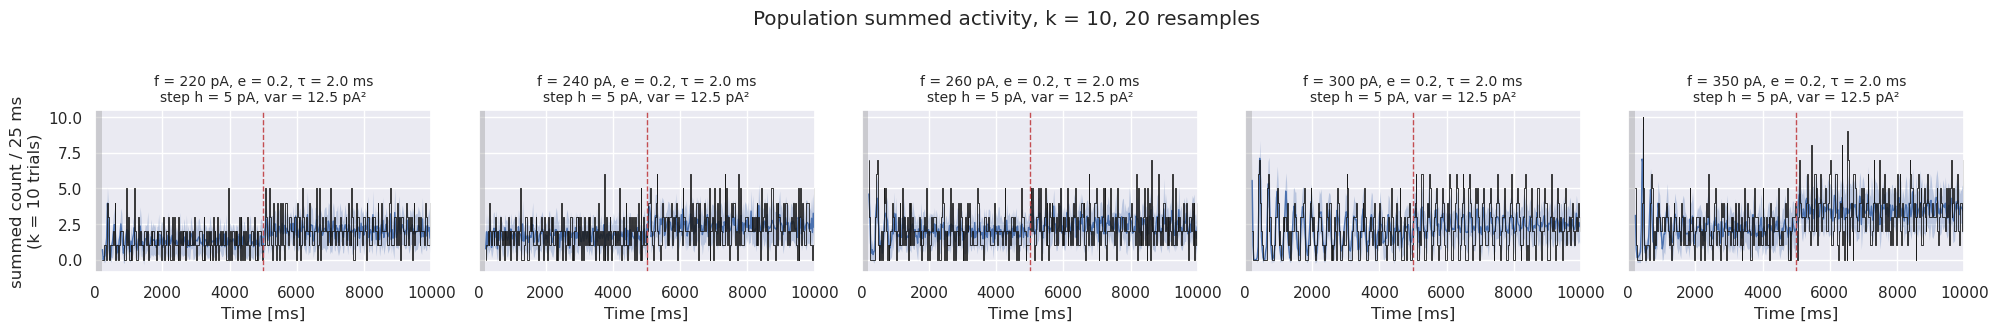

In [5]:
for v, h in EXAMPLES:
    fig, ax = plt.subplots(1, len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.2), sharey = True)
    for c, f in enumerate(EXAMPLE_F):
        X, t_bin = condition_psths(v, h, f)
        t = t_bin - PSTH_BIN/2
        mu, sd = X.mean(0), X.std(0)
        ax[c].fill_between(t, mu - sd, mu + sd, color = 'C0', alpha = 0.3, lw = 0)
        ax[c].plot(t, mu, color = 'C0', lw = 1)
        ax[c].step(t, X[0], where = 'mid', color = 'k', lw = 0.6)
        ax[c].axvline(true_cp, color = 'r', ls = '--', lw = 1)
        ax[c].axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
        ax[c].set_xlim(0, T)
        ax[c].set_title(title_cp(f, v, h), fontsize = 10)
        ax[c].set_xlabel('Time [ms]')
    ax[0].set_ylabel(f'summed count / {PSTH_BIN} ms\n(k = {K} trials)')
    fig.suptitle(f'Population summed activity, k = {K}, {N_RES} resamples', y = 1.03)
    fig.tight_layout()
    if SAVE: plt.savefig(f'./plots/population/{tag}_library_summed_activity_v{v}_h{h}.png', bbox_inches = 'tight')
    plt.show()

## 2. Pre- and post-change spike count distributions
Bin values (count + 1) pooled over the 20 resamples, split at the true CP (`reference_bins`). These are the distributions the nonparametric divergences in section 6 compare. As f grows, bursting widens both distributions, so they overlap more even when the means move apart.

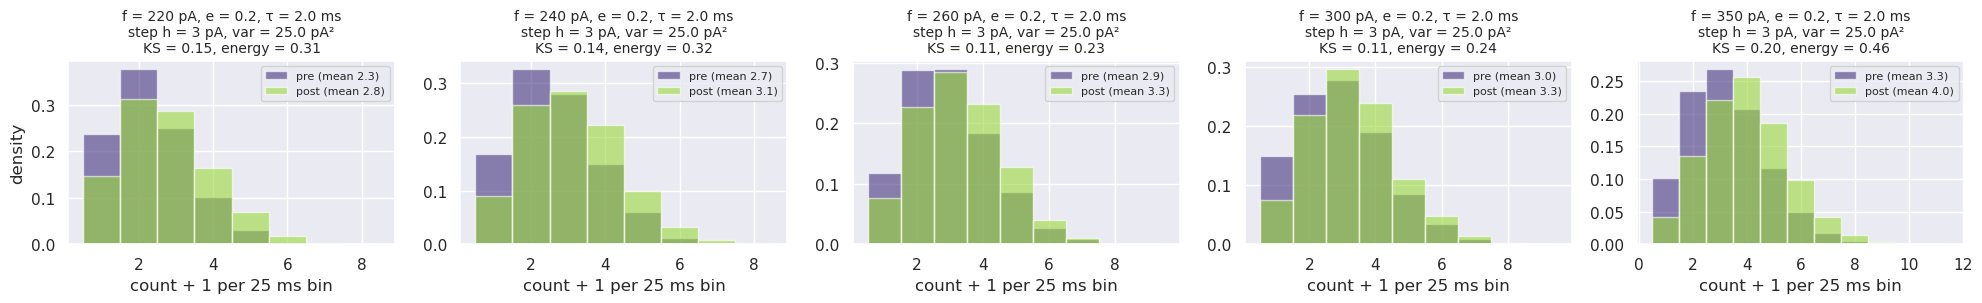

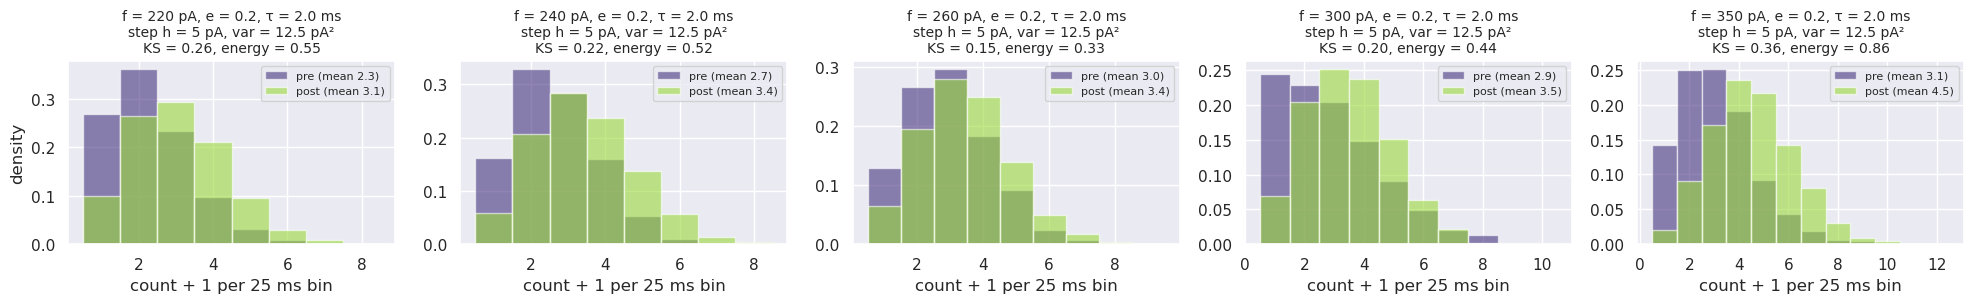

In [6]:
for v, h in EXAMPLES:
    fig, ax = plt.subplots(1, len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.2))
    for c, f in enumerate(EXAMPLE_F):
        X, t_bin = condition_psths(v, h, f)
        pre, post = reference_bins(X + 1., t_bin, PSTH_BIN, true_cp)
        bins = np.arange(min(pre.min(), post.min()) - 0.5, max(pre.max(), post.max()) + 1.5)
        ax[c].hist(pre, bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = f'pre (mean {pre.mean():.1f})')
        ax[c].hist(post, bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = f'post (mean {post.mean():.1f})')
        d = empirical_distances(pre, post)
        ax[c].set_title(title_cp(f, v, h) + f'\nKS = {d["KS distance"]:.2f}, energy = {d["energy distance"]:.2f}', fontsize = 10)
        ax[c].set_xlabel(f'count + 1 per {PSTH_BIN} ms bin')
        ax[c].legend(fontsize = 8)
    ax[0].set_ylabel('density')
    fig.tight_layout()
    if SAVE: plt.savefig(f'./plots/population/{tag}_library_count_dists_v{v}_h{h}.png', bbox_inches = 'tight')
    plt.show()

## 3. Worked example
One PSTH (resample 0) for f = 0 and f = 400 at var = 12.5, h = 20, with each detector's score trace under it. Blue dotted line: estimated CP (it includes the SST/ESST shift, so it sits a few bins right of their raw peaks). Red dashed line: true CP. uLSIF and RuLSIF often show two peaks, one window either side of the change. For e-divisive the trace is the drop in energy cost from splitting at each bin, and the CP is its argmax.

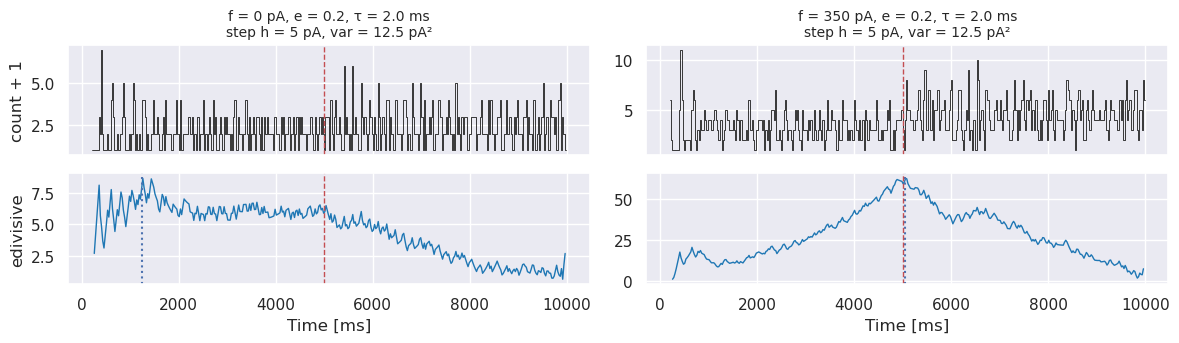

In [16]:
v, h = EXAMPLES[1]
fig, ax = plt.subplots(1 + len(METHODS), 2, figsize = (12, 1.8*(1 + len(METHODS))), sharex = True)
for c, f in enumerate([0, 350]):
    X, t_bin = condition_psths(v, h, f)
    x, t = X[0] + 1., t_bin - PSTH_BIN/2
    ax[0, c].step(t, x, where = 'mid', color = 'k', lw = 0.6)
    ax[0, c].set_title(title_cp(f, v, h), fontsize = 10)
    for r, m in enumerate(METHODS, start = 1):
        CP, score, s = library_cp(x, t_bin, PSTH_BIN, m, return_trace = True)
        ax[r, c].plot(t, s, color = COLORS[m], lw = 1)
        ax[r, c].axvline(CP, color = 'b', ls = ':', lw = 1.5)
        ax[r, 0].set_ylabel(m)
    for a in ax[:, c]:
        a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
    ax[-1, c].set_xlabel('Time [ms]')
ax[0, 0].set_ylabel('count + 1')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/population/{tag}_library_worked_example.png', bbox_inches = 'tight')
plt.show()

In [8]:
res = {}
for m in METHODS:
    try:
        with open(f'CPA_psth_{cp}_{tag}_{m}_bin{PSTH_BIN}.pickle', 'rb') as file:
            res[m] = pickle.load(file)
    except FileNotFoundError:
        print(f'missing: CPA_psth_{cp}_{tag}_{m}_bin{PSTH_BIN}.pickle')
f_order = np.sort(saved['f_values'])[::-1].tolist()     # f = 0 (darkest) drawn last, on top
variances = np.sort(saved['var'])

## 4. L2 change point error
RMS error sqrt(mean (CP − true CP)²) over the 20 resamples of each condition (`cp_error_norms`). One figure per method, one panel per noise variance, coloured by f. At h = 0 there is no change, so the error there is the chance level.

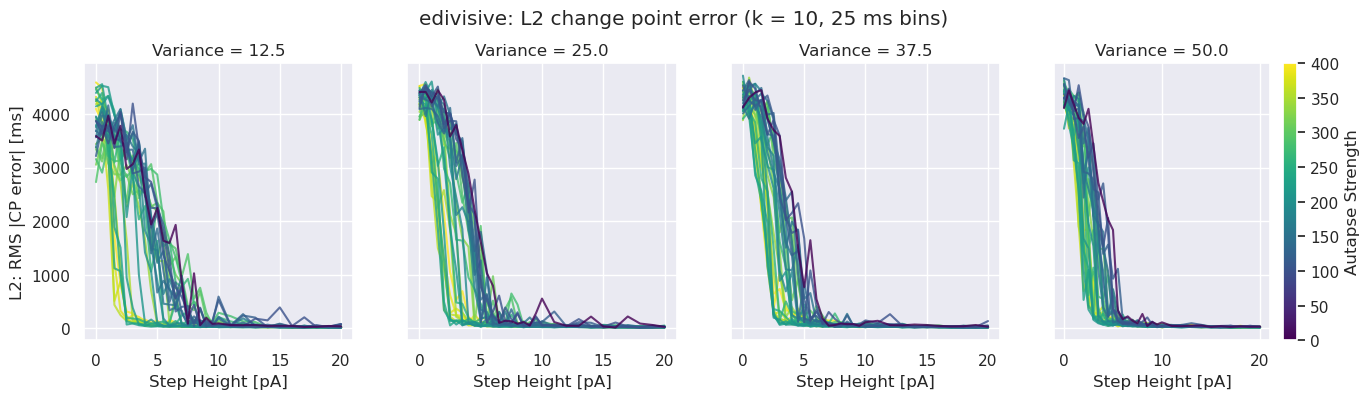

In [9]:
norms = {m: cp_error_norms(r, true_cp, group_cols = ('autapse f', 'variance', STEP)) for m, r in res.items()}
for m, df in norms.items():
    fig, ax = plt.subplots(1, len(variances), figsize = (4*len(variances), 3.6), sharey = True)
    for n, v in enumerate(variances):
        fig, ax[n] = psychometric_curve(df[df['variance'] == v], x = STEP, y = 'L2 |error|', hue_order = f_order,
                                        fig = fig, ax = ax[n], add_colorbar = n == len(variances) - 1)
        ax[n].set_title(f'Variance = {v}')
        ax[n].set_xlabel(STEP_LABEL)
    ax[0].set_ylabel('L2: RMS |CP error| [ms]')
    fig.suptitle(f'{m}: L2 change point error (k = {K}, {PSTH_BIN} ms bins)', y = 1.03)
    if SAVE: plt.savefig(f'./plots/population/{tag}_library_{m}_L2.png', bbox_inches = 'tight')
    plt.show()

L2 error averaged over step heights > 0 against f, all methods side by side (one line per variance).

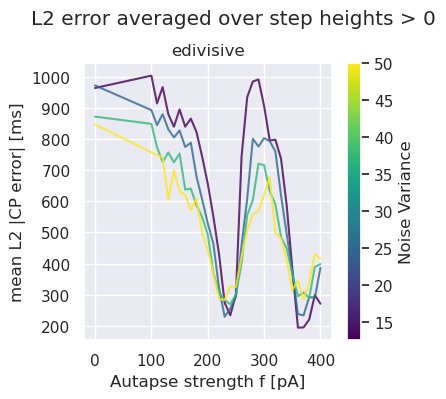

In [10]:
fig, ax = plt.subplots(1, len(norms), figsize = (4*len(norms), 3.6), sharey = True, squeeze = False)
ax = ax[0]
for n, (m, df) in enumerate(norms.items()):
    avg = curve_auc(df[df[STEP] > 0], x = STEP, y = 'L2 |error|', group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(avg, y = 'AUC', fig = fig, ax = ax[n], errorbar = None, add_colorbar = n == len(norms) - 1)
    ax[n].set_title(m)
    ax[n].set_xlabel('Autapse strength f [pA]')
ax[0].set_ylabel('mean L2 |CP error| [ms]')
fig.suptitle('L2 error averaged over step heights > 0', y = 1.03)
if SAVE: plt.savefig(f'./plots/population/{tag}_library_L2_vs_f.png', bbox_inches = 'tight')
plt.show()

Minimum detectable step (`min_step_below`): for each f and noise variance, the smallest step height from which the L2 error stays below the threshold for every larger step. A single noisy dip below the threshold does not count. One row per threshold (100–500 ms), one column per method. Gaps mean the error never drops below the threshold in the tested range.

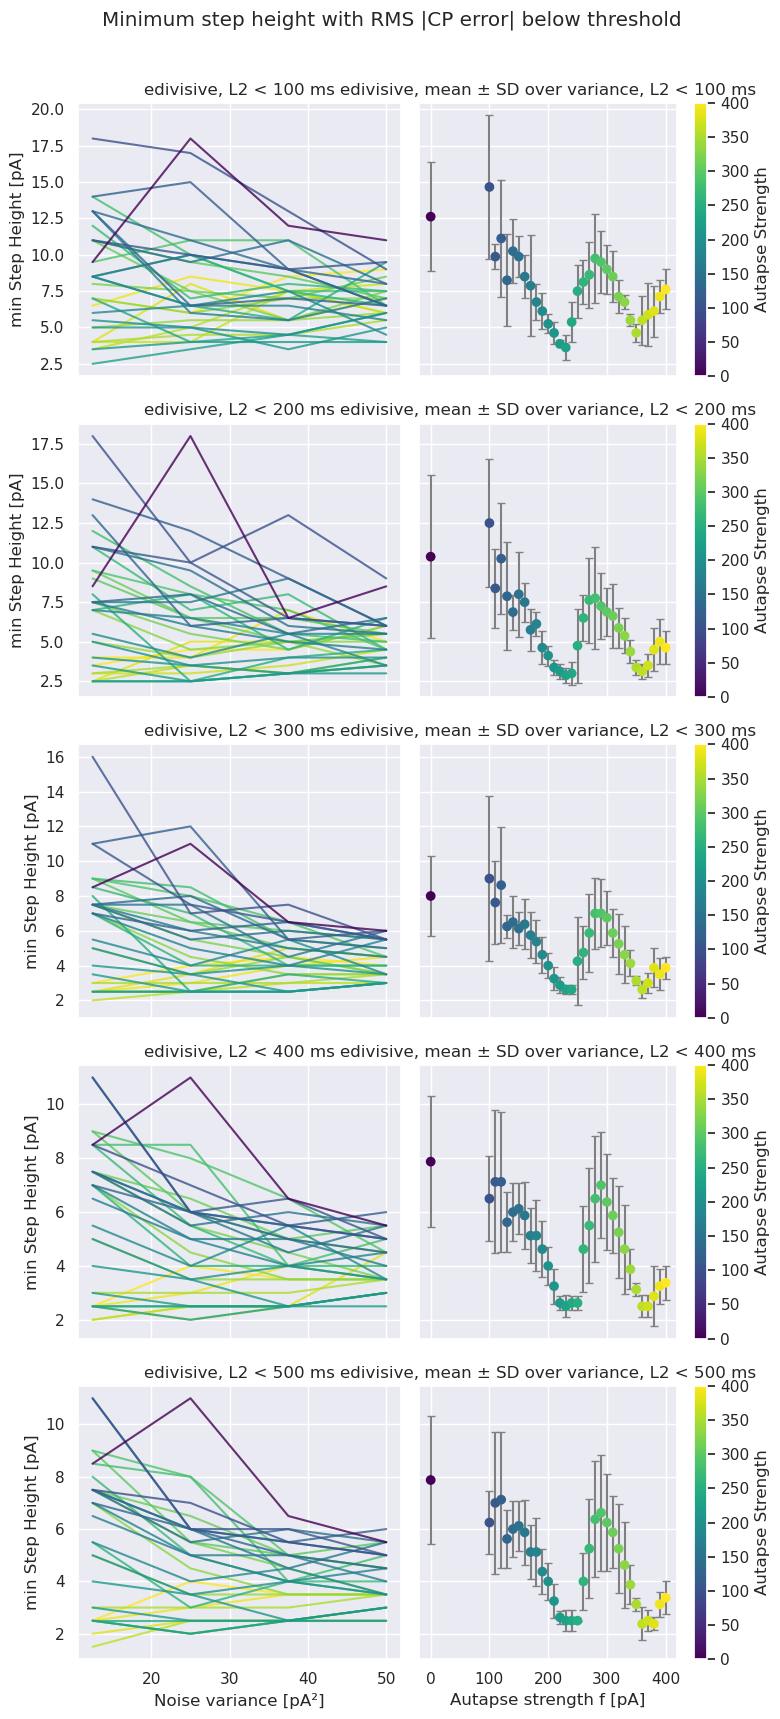

In [11]:
L2_THRS = [100, 200, 300, 400, 500]    # ms
f_lim = dict(vmin = min(saved['f_values']), vmax = max(saved['f_values']))

fig, ax = plt.subplots(len(L2_THRS), len(norms) + 1, figsize = (4*(len(norms) + 1), 3.4*len(L2_THRS)),
                       sharex = 'col', sharey = 'row', squeeze = False)
for r, thr in enumerate(L2_THRS):
    for n, (m, df) in enumerate(norms.items()):
        h_min = min_step_below(df, thr, step_col = STEP)
        fig, ax[r, n] = psychometric_curve(h_min, x = 'variance', y = STEP, hue_order = f_order,
                                           fig = fig, ax = ax[r, n], add_colorbar = False)
        ax[r, n].set_title(f'{m}, L2 < {thr} ms')
        ax[r, n].set_xlabel('Noise variance [pA²]' if r == len(L2_THRS) - 1 else '')
        ax[r, n].set_ylabel(f'min {STEP_LABEL}' if n == 0 else '')
    # extra column: each edivisive curve's mean ± SD over noise levels (NaN levels skipped)
    avg = min_step_below(norms['edivisive'], thr, step_col = STEP).groupby('autapse f')[STEP].agg(['mean', 'std'])
    ax[r, -1].errorbar(avg.index, avg['mean'], yerr = avg['std'], fmt = 'none', ecolor = 'grey', capsize = 3, zorder = 2)
    sc = ax[r, -1].scatter(avg.index, avg['mean'], c = avg.index, cmap = 'viridis', **f_lim, zorder = 3)
    fig.colorbar(sc, ax = ax[r, -1], label = 'Autapse Strength')
    ax[r, -1].set_title(f'edivisive, mean ± SD over variance, L2 < {thr} ms')
    ax[r, -1].set_xlabel('Autapse strength f [pA]' if r == len(L2_THRS) - 1 else '')
fig.suptitle('Minimum step height with RMS |CP error| below threshold', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/population/{tag}_library_min_step_L2.png', bbox_inches = 'tight')
plt.show()

## 5. AUC
Null-trial ROC (`tolerance_roc`) sweeps the tolerance: TPR(tol) = P(|err| ≤ tol | step h) and FPR(tol) = P(|err| ≤ tol | h = 0, same f and variance). AUC = 0.5 means the estimates land no closer to the true CP than with no change at all. With 20 resamples per condition each AUC is noisy (≈ ±0.1).

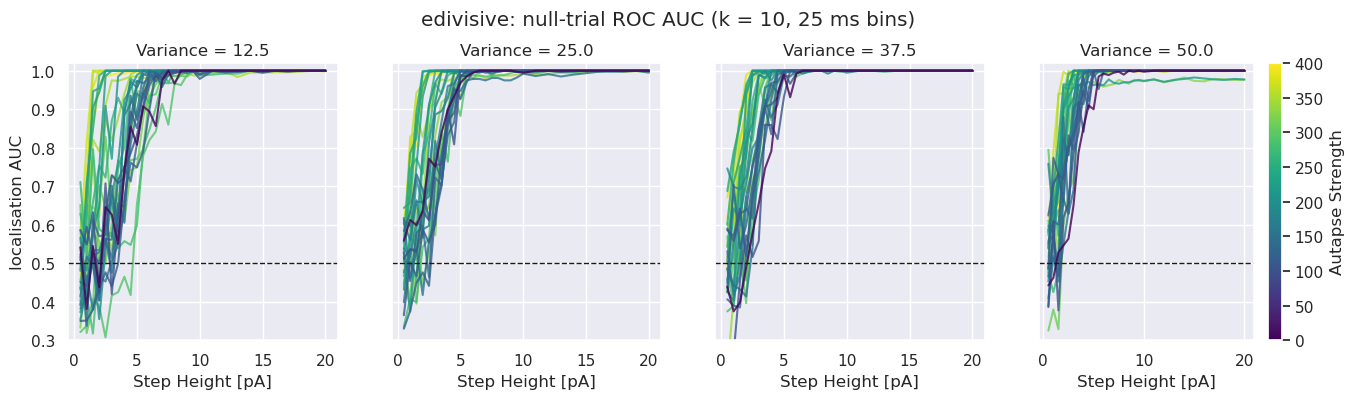

In [12]:
roc_auc = {m: tolerance_roc(r, true_cp, step_col = STEP)[1] for m, r in res.items()}
for m, df in roc_auc.items():
    fig, ax = plt.subplots(1, len(variances), figsize = (4*len(variances), 3.6), sharey = True)
    for n, v in enumerate(variances):
        fig, ax[n] = psychometric_curve(df[df['variance'] == v], x = STEP, y = 'AUC', hue_order = f_order,
                                        fig = fig, ax = ax[n], add_colorbar = n == len(variances) - 1)
        ax[n].axhline(0.5, color = 'k', ls = '--', lw = 1)
        ax[n].set_ylim(0.3, 1.02)
        ax[n].set_title(f'Variance = {v}')
        ax[n].set_xlabel(STEP_LABEL)
    ax[0].set_ylabel('localisation AUC')
    fig.suptitle(f'{m}: null-trial ROC AUC (k = {K}, {PSTH_BIN} ms bins)', y = 1.03)
    if SAVE: plt.savefig(f'./plots/population/{tag}_library_{m}_AUC.png', bbox_inches = 'tight')
    plt.show()

AUC averaged over step heights (`curve_auc`, normalised) against f, one panel per method.

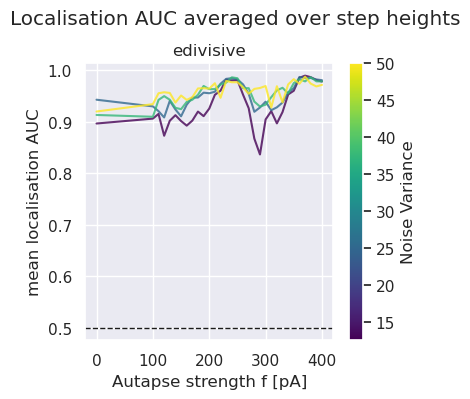

In [13]:
fig, ax = plt.subplots(1, len(roc_auc), figsize = (4*len(roc_auc), 3.6), sharey = True, squeeze = False)
ax = ax[0]
for n, (m, df) in enumerate(roc_auc.items()):
    avg = curve_auc(df, x = STEP, y = 'AUC', group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(avg, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n == len(roc_auc) - 1)
    ax[n].axhline(0.5, color = 'k', ls = '--', lw = 1)
    ax[n].set_title(m)
    ax[n].set_xlabel('Autapse strength f [pA]')
ax[0].set_ylabel('mean localisation AUC')
fig.suptitle('Localisation AUC averaged over step heights', y = 1.03)
if SAVE: plt.savefig(f'./plots/population/{tag}_library_AUC_vs_f.png', bbox_inches = 'tight')
plt.show()

## 6. Nonparametric divergences between the pre and post counts
Model-free distances between the pooled pre and post bin values (`empirical_distances`), one value per condition. They do not depend on the detector, because every method scored the same resamples.

| measure | meaning |
|---|---|
| `KS distance` | largest gap between the pre and post ECDFs, 0–1 |
| `energy distance` | energy distance of the counts (count units) |
| `energy distance (log)` | energy distance of log(count + 1), less sensitive to the overall rate |

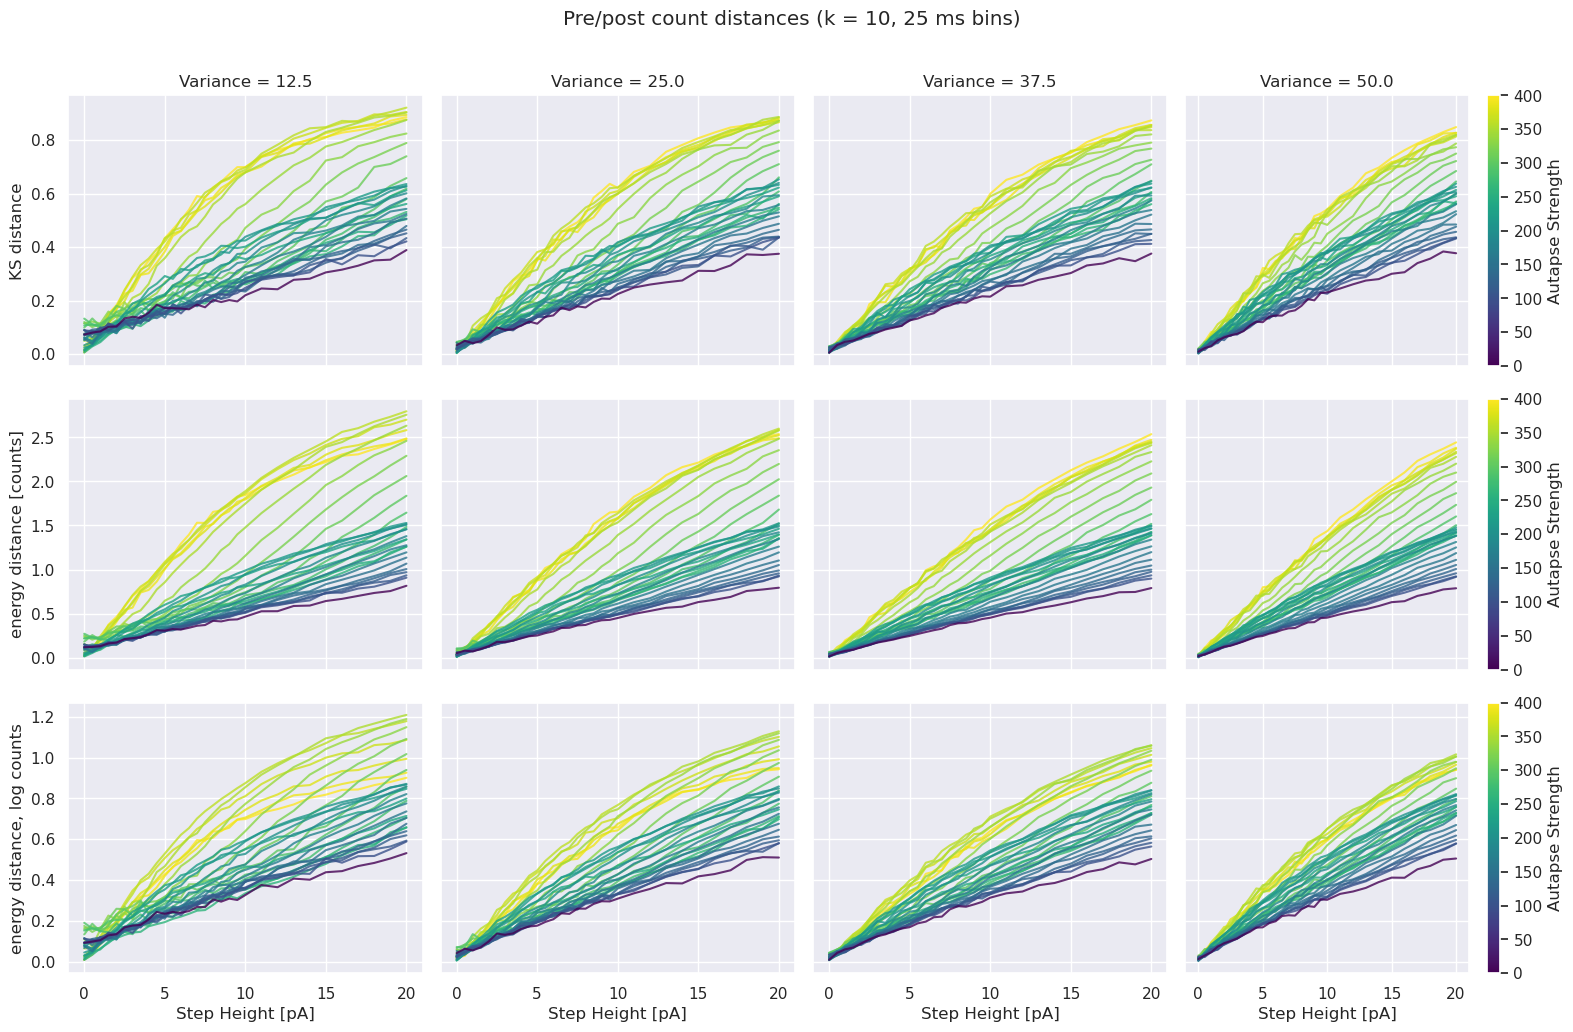

In [14]:
EMPIRICAL = {'KS distance': 'KS distance', 'energy distance': 'energy distance [counts]',
             'energy distance (log)': 'energy distance, log counts'}
cond = next(iter(res.values())).drop_duplicates(['autapse f', 'variance', STEP])

fig, ax = plt.subplots(len(EMPIRICAL), len(variances), figsize = (4*len(variances), 3.4*len(EMPIRICAL)),
                       sharey = 'row', sharex = True)
for r, (y, label) in enumerate(EMPIRICAL.items()):
    for n, v in enumerate(variances):
        fig, ax[r, n] = psychometric_curve(cond[cond['variance'] == v], x = STEP, y = y, hue_order = f_order,
                                           fig = fig, ax = ax[r, n], add_colorbar = n == len(variances) - 1)
        ax[r, n].set_ylabel(label if n == 0 else '')
        ax[r, n].set_title(f'Variance = {v}' if r == 0 else '')
        ax[r, n].set_xlabel(STEP_LABEL if r == len(EMPIRICAL) - 1 else '')
fig.suptitle(f'Pre/post count distances (k = {K}, {PSTH_BIN} ms bins)', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/population/{tag}_library_empirical_distances.png', bbox_inches = 'tight')
plt.show()

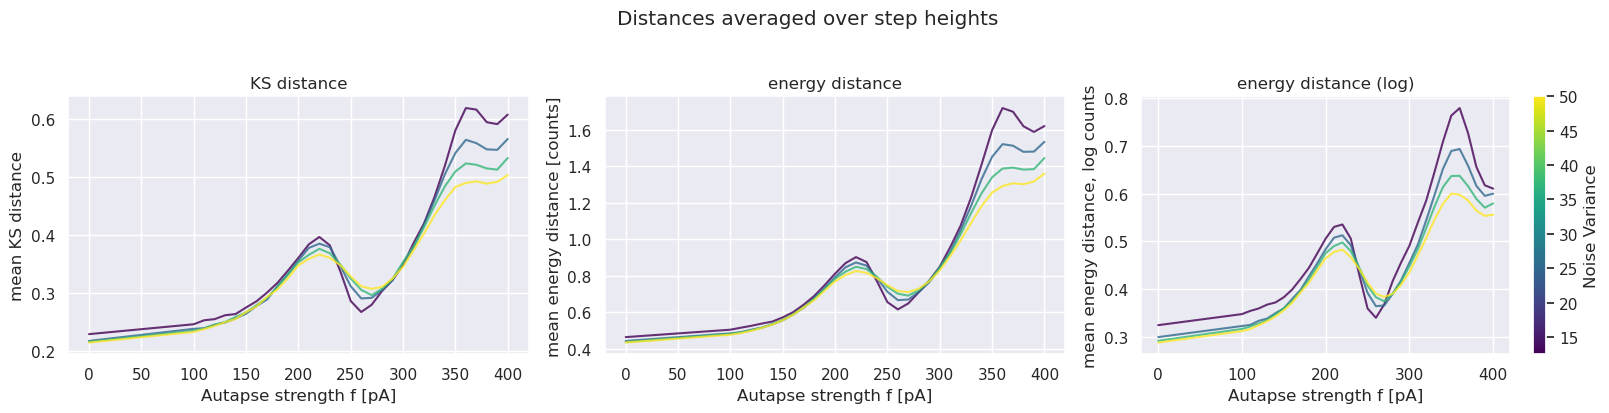

In [15]:
fig, ax = plt.subplots(1, len(EMPIRICAL), figsize = (5.5*len(EMPIRICAL), 4), squeeze = False)
ax = ax[0]
for n, (y, label) in enumerate(EMPIRICAL.items()):
    avg = curve_auc(cond, x = STEP, y = y, group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(avg, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n == len(EMPIRICAL) - 1)
    ax[n].set_title(y)
    ax[n].set_ylabel(f'mean {label}')
    ax[n].set_xlabel('Autapse strength f [pA]')
fig.suptitle('Distances averaged over step heights', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/population/{tag}_library_empirical_distances_vs_f.png', bbox_inches = 'tight')
plt.show()